In [1]:
# Persiapan Library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
print(os.listdir())

['analisis_top10.ipynb', 'IMDB top 1000.csv', 'IMDb Top 1000.xlsx', '~$IMDb Top 1000.xlsx']


In [2]:
#Load data (Bukti Data 1000 Baris)
df = pd.read_excel("IMDB top 1000.xlsx")
print(df.shape) # Bukti 1000 baris
display(df.head(1000)) # Bukti 1000 baris

(1000, 10)


,Colomns1,Title,Certificate,Duration,Genre,Rate,Metascore,Description,Cast,Info
0,0,1. The Shawshank Redemption (1994),R,142 min,Drama,93,80.0,Two imprisoned men bond over a number of years...,"Director: Frank Darabont | Stars: Tim Robbins,...","Votes: 2,295,987 | Gross: $28.34M"
1,1,2. The Godfather (1972),R,175 min,"Crime, Drama",92,100.0,The aging patriarch of an organized crime dyna...,Director: Francis Ford Coppola | Stars: Marlon...,"Votes: 1,584,782 | Gross: $134.97M"
2,2,3. The Dark Knight (2008),PG-13,152 min,"Action, Crime, Drama",90,84.0,When the menace known as the Joker wreaks havo...,Director: Christopher Nolan | Stars: Christian...,"Votes: 2,260,649 | Gross: $534.86M"
3,3,4. The Godfather: Part II (1974),R,202 min,"Crime, Drama",90,90.0,The early life and career of Vito Corleone in ...,Director: Francis Ford Coppola | Stars: Al Pac...,"Votes: 1,107,253 | Gross: $57.30M"
4,4,5. The Lord of the Rings: The Return of the Ki...,PG-13,201 min,"Action, Adventure, Drama",89,94.0,Gandalf and Aragorn lead the World of Men agai...,"Director: Peter Jackson | Stars: Elijah Wood, ...","Votes: 1,614,369 | Gross: $377.85M"
...,...,...,...,...,...,...,...,...,...,...
995,995,398. Scent of a Woman (1992),R,156 min,Drama,80,NaN,A prep school student needing money agrees to ...,"Director: Martin Brest | Stars: Al Pacino, Chr...","Votes: 256,515 | Gross: $63.90M"
996,996,399. Aladdin (1992),G,90 min,"Animation, Adventure, Comedy",80,86.0,A kindhearted street urchin and a power-hungry...,"Directors: Ron Clements, John Musker | Stars: ...","Votes: 367,489 | Gross: $217.35M"
997,997,400. JFK (1991),R,189 min,"Drama, History, Thriller",80,72.0,New Orleans District Attorney Jim Garrison dis...,"Director: Oliver Stone | Stars: Kevin Costner,...","Votes: 139,634 | Gross: $70.41M"
998,998,301. Nights of Cabiria (1957),Not Rated,110 min,Drama,81,NaN,A waifish prostitute wanders the streets of Ro...,Director: Federico Fellini | Stars: Giulietta ...,"Votes: 42,160 | Gross: $0.75M"


In [3]:
# METODE: Validasi Struktur Data Analysis / Validasi Awal
print("=== Cek data Rusak & Kotor ===")
df.info() # BUKTI: Rate masih int64 (80, 93), ada Column1
print(df["Rate"].min()) # BUKTI: 80 

=== Cek data Rusak & Kotor ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Colomns1     1000 non-null   int64  
 1   Title        1000 non-null   object 
 2   Certificate  973 non-null    object 
 3   Duration     1000 non-null   object 
 4   Genre        1000 non-null   object 
 5   Rate         1000 non-null   int64  
 6   Metascore    712 non-null    float64
 7   Description  1000 non-null   object 
 8   Cast         1000 non-null   object 
 9   Info         1000 non-null   object 
dtypes: float64(1), int64(2), object(7)
memory usage: 78.3+ KB
80


In [5]:
print(" === Data Kosong & Kotor === ")
print(df.isnull().sum())

 === Data Kosong & Kotor === 
Colomns1         0
Title            0
Certificate     27
Duration         0
Genre            0
Rate             0
Metascore      288
Description      0
Cast             0
Info             0
dtype: int64


In [6]:
# METODE: Data Cleaning / Preprocessing
print("=== Cleaning Data ===")
df = df.loc[:, ~df.columns.str.contains('^Unnamed|Column1')]
for col in df.columns:
    if 'column1' in col.lower() or 'colomns1' in col.lower():
        df = df.rename(columns={col: 'No'})

# 1. Ubah int jadi float dan bagi 10
# 80 -> 8.0 , 93 -> 9.3
df["No"] = df["No"].astype(int) 
df["Rate"] = df["Rate"].astype(float) / 10.0

print(f"Setelah cleaning: {df.shape}") # (1000, 9)
df.info() # Harusnya Rate sekarang float64
print(f"Rate terkecil: {df['Rate'].min()}") # Akan jadi 8.0
print(f"Rate terbesar: {df['Rate'].max()}") # Akan jadi 9.3
print("Cleaning Selesai")

=== Cleaning Data ===
Setelah cleaning: (1000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   No           1000 non-null   int64  
 1   Title        1000 non-null   object 
 2   Certificate  973 non-null    object 
 3   Duration     1000 non-null   object 
 4   Genre        1000 non-null   object 
 5   Rate         1000 non-null   float64
 6   Metascore    712 non-null    float64
 7   Description  1000 non-null   object 
 8   Cast         1000 non-null   object 
 9   Info         1000 non-null   object 
dtypes: float64(2), int64(1), object(7)
memory usage: 78.3+ KB
Rate terkecil: 8.0
Rate terbesar: 9.3
Cleaning Selesai


In [7]:
# Melihat columns yang ada setelah cleaning
print(df.columns.tolist())

['No', 'Title', 'Certificate', 'Duration', 'Genre', 'Rate', 'Metascore', 'Description', 'Cast', 'Info']


In [8]:
# Memberikan bukti bahwa kolom sampah sudah hilang
print("\nKolom sampah masih ada gak?")
print("Unnamed" in str(df.columns) or "Column1" in df.columns) 


Kolom sampah masih ada gak?
False


In [9]:
print("=== Pembuktian 1000 Baris ===")
print(f"Bentuk data: {df.shape}") # Harus (1000, 10) - LOLOS
print(f"Jumlah baris: {len(df)}")
print(f"Jumlah baris pakai shape: {df.shape[0]}")
print(f"Baris 0 sampai {len(df)-1} = total {len(df)} data")

=== Pembuktian 1000 Baris ===
Bentuk data: (1000, 10)
Jumlah baris: 1000
Jumlah baris pakai shape: 1000
Baris 0 sampai 999 = total 1000 data


In [10]:
# Statistik Deskriptif
print("=== Statistik Rate ===")
df["Rate"].describe()


=== Statistik Rate ===


count    1000.000000
mean        8.097500
std         0.169566
min         8.000000
25%         8.000000
50%         8.000000
75%         8.100000
max         9.300000
Name: Rate, dtype: float64

In [11]:
print( " === Sorting & Ranking Top 10 Film Terbaik === ")
# Urutkan semua data dulu dari tertinggi ke terendah
top10 = df.sort_values(by="Rate", ascending=False).head(10)
print(df.columns.tolist())

# Tampilkan hasil top 10
print("10 Film Terbaik IMDB:")
top10[["No", "Title",  "Certificate", "Duration", "Genre", "Rate", "Metascore", "Description", "Cast"]]

 === Sorting & Ranking Top 10 Film Terbaik === 
['No', 'Title', 'Certificate', 'Duration', 'Genre', 'Rate', 'Metascore', 'Description', 'Cast', 'Info']
10 Film Terbaik IMDB:


,No,Title,Certificate,Duration,Genre,Rate,Metascore,Description,Cast
0,0,1. The Shawshank Redemption (1994),R,142 min,Drama,9.3,80.0,Two imprisoned men bond over a number of years...,"Director: Frank Darabont | Stars: Tim Robbins,..."
1,1,2. The Godfather (1972),R,175 min,"Crime, Drama",9.2,100.0,The aging patriarch of an organized crime dyna...,Director: Francis Ford Coppola | Stars: Marlon...
3,3,4. The Godfather: Part II (1974),R,202 min,"Crime, Drama",9.0,90.0,The early life and career of Vito Corleone in ...,Director: Francis Ford Coppola | Stars: Al Pac...
2,2,3. The Dark Knight (2008),PG-13,152 min,"Action, Crime, Drama",9.0,84.0,When the menace known as the Joker wreaks havo...,Director: Christopher Nolan | Stars: Christian...
4,4,5. The Lord of the Rings: The Return of the Ki...,PG-13,201 min,"Action, Adventure, Drama",8.9,94.0,Gandalf and Aragorn lead the World of Men agai...,"Director: Peter Jackson | Stars: Elijah Wood, ..."
7,7,8. 12 Angry Men (1957),Approved,96 min,"Crime, Drama",8.9,96.0,A jury holdout attempts to prevent a miscarria...,"Director: Sidney Lumet | Stars: Henry Fonda, L..."
5,5,6. Pulp Fiction (1994),R,154 min,"Crime, Drama",8.9,94.0,"The lives of two mob hitmen, a boxer, a gangst...",Director: Quentin Tarantino | Stars: John Trav...
6,6,7. Schindler's List (1993),R,195 min,"Biography, Drama, History",8.9,94.0,"In German-occupied Poland during World War II,...",Director: Steven Spielberg | Stars: Liam Neeso...
10,10,11. The Lord of the Rings: The Fellowship of t...,PG-13,178 min,"Action, Adventure, Drama",8.8,92.0,A meek Hobbit from the Shire and eight compani...,"Director: Peter Jackson | Stars: Elijah Wood, ..."
12,12,"13. The Good, the Bad and the Ugly (1966)",R,178 min,Western,8.8,90.0,A bounty hunting scam joins two men in an unea...,Director: Sergio Leone | Stars: Clint Eastwood...


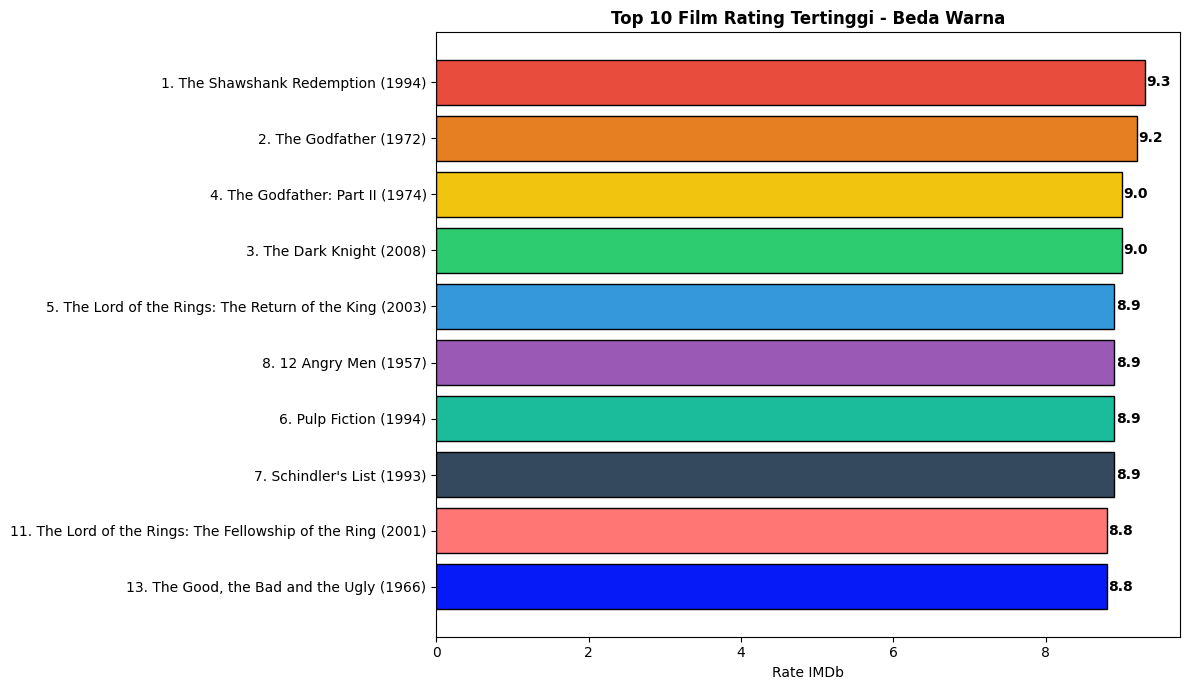

In [12]:
top10 = df.sort_values(by="Rate", ascending=False).head(10)

warna_top10 = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#3498db','#9b59b6','#1abc9c','#34495e','#ff7675',"#061af8"]

plt.figure(figsize=(12,7))
plt.barh(top10["Title"][::-1], top10["Rate"][::-1], color=warna_top10[::-1], edgecolor='black')
plt.xlabel("Rate IMDb")
plt.title("Top 10 Film Rating Tertinggi - Beda Warna", fontweight='bold')
for i, v in enumerate(top10["Rate"][::-1]):
    plt.text(v + 0.02, i, str(v), va='center', fontweight='bold')
plt.tight_layout()
plt.show()

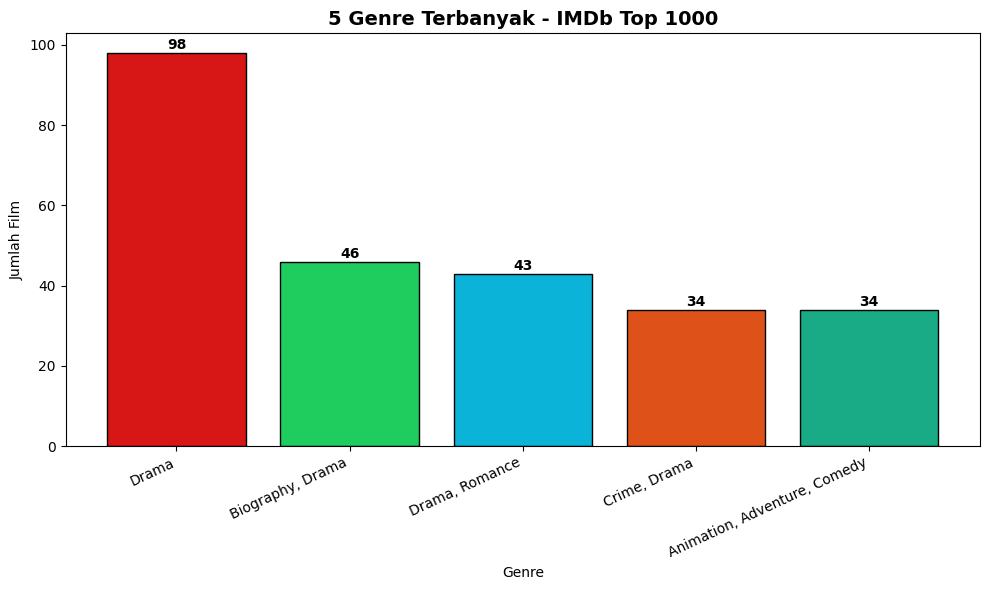

In [14]:

top_genre = df["Genre"].value_counts().head(5)

# 5 warna beda
warna = ["#D71616", "#1FCD5F", "#0BB3D9", "#DE5119", "#18AB86"]

plt.figure(figsize=(10,6))
plt.bar(top_genre.index, top_genre.values, color=warna, edgecolor='black')

plt.title("5 Genre Terbanyak - IMDb Top 1000", fontsize=14, fontweight='bold')
plt.xlabel("Genre")
plt.ylabel("Jumlah Film")
plt.xticks(rotation=25, ha='right')

# kasih angka di atas bar
for i, v in enumerate(top_genre.values):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [15]:
# === LANJUTAN: ALGORITMA MACHINE LEARNING (Paling Mudah) ===
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 1. Bikin Label Klasifikasi dari Rate yang udah bersih 8.0-9.3
# Ini biar jadi Klasifikasi
def label_film(r):
    if r >= 9.0:
        return "Masterpiece"
    elif r >= 8.5:
        return "Sangat Bagus"
    else:
        return "Bagus"

df ["Kategori"] = df["Rate"].apply(label_film)

# 2. Siapkan Fitur (X) dan Target (Y)
# Kita pakai Metascore buat nebak Kategori
# Hapus dulu yang Metascore nya kosong (sudah kamu cek kosong 288 di ss 3)
df_ml = df.dropna(subset=['Metascore'])

X = df_ml[["Metascore", "Rate"]]  # Fitur
y = df_ml["Kategori"]             # Target Klasifikasi

# 3. Bagi data Train dan Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Algoritma Decision Tree (Paling mudah dipahami)
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# 5. Prediksi dan Cek Akurasi
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"=== Hasil Machine Learning ===")
print(f"Jumlah data latih: {len(X_train)}")
print(f"Jumlah data test: {len(X_test)}")
print(f"Akurasi Decision Tree: {acc * 100:.2f}%")
print("\nContoh Prediksi:")
print(pd.DataFrame({"Metascore": X_test["Metascore"].head(), "Rate Asli": X_test["Rate"].head(), "Prediksi": y_pred[:5]}))

=== Hasil Machine Learning ===
Jumlah data latih: 569
Jumlah data test: 143
Akurasi Decision Tree: 100.00%

Contoh Prediksi:
     Metascore  Rate Asli Prediksi
709       73.0        8.1    Bagus
554       80.0        8.0    Bagus
288       75.0        8.1    Bagus
345       87.0        8.0    Bagus
612       87.0        8.1    Bagus


In [16]:
print(f"Tertinggi: {top10.iloc[0]['Title']} - {top10.iloc[0]['Rate']}")
print(f"Rata-rata Top 10: {top10['Rate'].mean():.2f}")

Tertinggi: 1. The Shawshank Redemption (1994) - 9.3
Rata-rata Top 10: 8.97


In [17]:
# Urutkan semua data dulu dari tertinggi ke terendah
df_sorted = df.sort_values(by="Rate", ascending=False)
top10 = df_sorted.head(10)

print(f"Film No 1/Tertinggi: {df_sorted.iloc[0]["Title"]} dengan Rate {df_sorted.iloc[0]["Rate"]}")
print(f"Film No 10: {df_sorted.iloc[9]["Title"]} dengan Rate {df_sorted.iloc[9]["Rate"]}")
print(f"Film Terendah (No 1000): {df_sorted.iloc[999]["Title"]} dengan Rate {df_sorted.iloc[999]["Rate"]}")
print(f"Rata-rata Rate Top 10: {top10["Rate"].mean():.2f}")
print(f"Genre paling dominan di Top 10: {top10["Genre"].value_counts().idxmax()}")

Film No 1/Tertinggi: 1. The Shawshank Redemption (1994) dengan Rate 9.3
Film No 10: 13. The Good, the Bad and the Ugly (1966) dengan Rate 8.8
Film Terendah (No 1000): 387. The Celebration (1998) dengan Rate 8.0
Rata-rata Rate Top 10: 8.97
Genre paling dominan di Top 10: Crime, Drama


In [18]:
df.to_csv('IMDB_cleaned_final.csv', index=False)
print("File siap upload ke GitHub")

File siap upload ke GitHub
